In [1]:
import numpy as np
import pandas as pd
import torch
import math
from torch import nn
import torch.nn.functional as F
import os
import numpy as np
import pandas as pd
import math
import random
import argparse
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

#from utility import evaluate_loader

In [1]:
import pandas as pd

In [3]:
berts = pd.read_pickle("./bert_emb.pickle")

In [4]:
len(berts)

9265

In [10]:
indices_null = np.where(S <= 1)[0]
len(indices_null)

546

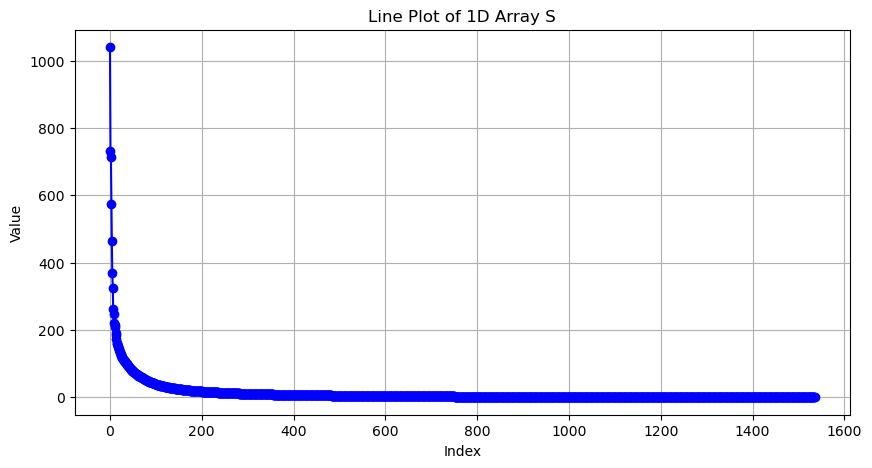

In [5]:
import matplotlib.pyplot as plt

wordvec_df = pd.read_pickle(os.path.join("", '3small_emb.pickle'))
word_vectors = np.stack(wordvec_df)
all_samples = word_vectors * 200
mean = np.mean(all_samples, axis=0)
cov = np.cov( all_samples - mean, rowvar=False)
U, S, VT = np.linalg.svd(cov, full_matrices=False)
plt.figure(figsize=(10, 5))
plt.plot(S, marker='o', linestyle='-', color='b')  # 用折线图展示数组
plt.title("Line Plot of 1D Array S")
plt.xlabel("Index")
plt.ylabel("Value")
plt.grid(True)
plt.show()

In [3]:
os.environ["CUDA_VISIBLE_DEVICES"] = str(3)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [4]:
class SeqDataset(Dataset):
    def __init__(self, data):
        self.seq_data = [torch.tensor(seq, dtype=torch.long) for seq in data['seq']]
        self.len_seq_data = [torch.tensor(len_seq, dtype=torch.long) for len_seq in data['len_seq']]
        self.next_data = [torch.tensor(next_val, dtype=torch.long) for next_val in data['next']]

    def __len__(self):
        return len(self.seq_data)

    def __getitem__(self, idx):
        return {'seq': self.seq_data[idx], 'len_seq': self.len_seq_data[idx], 'next': self.next_data[idx]}

In [5]:
data_statis = pd.read_pickle(os.path.join("", 'data_statis.df'))  # read data statistics, includeing seq_size and item_num
seq_size = data_statis['seq_size'][0]  # the length of history to define the seq
item_num = data_statis['item_num'][0]  # total number of items

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    # +str(args.cuda)
train_data = pd.read_pickle(os.path.join("", 'train_data.df'))
val_data = pd.read_pickle(os.path.join("", 'val_data.df'))
test_data = pd.read_pickle(os.path.join("", 'test_data.df'))

train_dataset = SeqDataset(train_data)
val_dataset = SeqDataset(val_data)
test_dataset = SeqDataset(test_data)

train_loader = DataLoader(train_dataset, batch_size=int(256))
val_loader = DataLoader(val_dataset, batch_size=int(256))
test_loader = DataLoader(test_dataset, batch_size=int(256))

In [6]:
wordvec_df = pd.read_pickle(os.path.join("", '3small_emb.pickle'))
word_vectors = np.stack(wordvec_df)
word_vectors = word_vectors*40
random_vector = np.random.randn(word_vectors.shape[1])  
word_vectors = np.vstack([word_vectors, random_vector])
item_embeddings = nn.Embedding.from_pretrained(torch.tensor(word_vectors,dtype=torch.float32),freeze=True,padding_idx=item_num)
item_embeddings = item_embeddings.to(device)

In [7]:
def predict(states):
   #hidden
   seq = item_embeddings(states)
   mask = torch.ne(states, item_num).float().unsqueeze(-1).to(device)
   seq *= mask

   mask = mask.sum(dim=1)  # 在维度2上求和，得到非零元素的数量
   # 然后计算 seq 在维度2上的和
   seq = seq.sum(dim=1)  # 在维度2上求和
   # 计算 seq 在维度2上的均值
   state_hidden = seq / mask
   x = state_hidden
   test_item_emb = item_embeddings.weight[:-1]
   scores = torch.matmul(x, test_item_emb.transpose(0, 1))

   return x,scores

In [8]:
def calculate_hit_loader(sorted_list,topk,true_items,hit_purchase,ndcg_purchase,mrr_purchase):
    true_items = true_items.tolist()
    for i in range(len(topk)):
        rec_list = sorted_list[:, -topk[i]:]
        # print(rec_list)
        # print(true_items)
        # print('...........')
        # break
        for j in range(len(true_items)):
            if true_items[j] in rec_list[j]:
                rank = topk[i] - np.argwhere(rec_list[j] == true_items[j])[0,0]
                # total_reward[i] += rewards[j]
                # if rewards[j] == r_click:
                #     hit_click[i] += 1.0
                #     ndcg_click[i] += 1.0 / np.log2(rank + 1)
                # else:
                hit_purchase[i] += 1.0
                ndcg_purchase[i] += 1.0 / np.log2(rank + 1)
                mrr_purchase[i] += 1.0/ rank
    
def evaluate_loader(val_loader, device):

    total_purchase = 0.0
    hit_purchase=[0,0,0,0,0]
    ndcg_purchase=[0,0,0,0,0]
    mrr_purchase = [0,0,0,0,0]
    topk = [1,5,10,20,50]

    for batch in val_loader:
        seq = batch["seq"].to(device)
        len_seq = batch["len_seq"]
        target = batch["next"]

        #_, prediction = model.predict(seq, diff)
        _, prediction = predict(seq) # args.linespace
        #print(prediction.shape)
        _, topK = prediction.topk(100, dim=1, largest=True, sorted=True)
        topK = topK.cpu().detach().numpy()
        sorted_list2=np.flip(topK,axis=1)
        calculate_hit_loader(sorted_list2,topk,target,hit_purchase,ndcg_purchase,mrr_purchase)
        total_purchase+=len(seq)

    hr_list = []
    ndcg_list = []
    mrr_list = []
    for i in range(len(topk)):
        hr_purchase=hit_purchase[i]/total_purchase
        ng_purchase=ndcg_purchase[i]/total_purchase
        mr_purchase=mrr_purchase[i]/total_purchase
        hr_list.append(hr_purchase)
        ndcg_list.append(ng_purchase)
        mrr_list.append(mr_purchase)
    print('{:<10s} {:<10s} {:<10s} '.format("ACC","ACC","ACC"))
    print('{:<10.6f} {:<10.6f} {:<10.6f}'.format(hr_list[0], (ndcg_list[0]), mrr_list[0]))
    print('{:<10s} {:<10s} {:<10s} {:<10s}'.format('HR@'+str(topk[1]), 'HR@'+str(topk[2]), 'HR@'+str(topk[3]), 'HR@'+str(topk[4])))
    print('{:<10.6f} {:<10.6f} {:<10.6f} {:<10.6f}'.format(hr_list[1], (hr_list[2]), hr_list[3], hr_list[4]))
    print('{:<10s} {:<10s} {:<10s} {:<10s}'.format('NDCG@'+str(topk[1]), 'NDCG@'+str(topk[2]), 'NDCG@'+str(topk[3]), 'NDCG@'+str(topk[4])))
    print('{:<10.6f} {:<10.6f} {:<10.6f} {:<10.6f}'.format(ndcg_list[1], (ndcg_list[2]), ndcg_list[3], ndcg_list[4]))
    print('{:<10s} {:<10s} {:<10s} {:<10s}'.format('MRR@'+str(topk[1]), 'MRR@'+str(topk[2]), 'MRR@'+str(topk[3]), 'MRR@'+str(topk[4])))
    print('{:<10.6f} {:<10.6f} {:<10.6f} {:<10.6f}'.format(mrr_list[1], (mrr_list[2]), mrr_list[3], mrr_list[4]))

    return hr_list, ndcg_list

In [9]:
_,_ = evaluate_loader(test_loader, device)

ACC        ACC        ACC        
0.001005   0.001005   0.001005  
HR@5       HR@10      HR@20      HR@50     
0.005784   0.010810   0.018058   0.033275  
NDCG@5     NDCG@10    NDCG@20    NDCG@50   
0.003312   0.004922   0.006745   0.009744  
MRR@5      MRR@10     MRR@20     MRR@50    
0.002512   0.003167   0.003662   0.004136  


## SID

In [20]:
import pickle, numpy as np, faiss, os

# 读取你的向量 (N, d)
wordvec_df   = pickle.load(open('3small_emb.pickle', 'rb'))
word_vectors = np.stack(wordvec_df).astype('float32')
all_samples = word_vectors * 40
mean = np.mean(all_samples, axis=0)
cov = np.cov( all_samples - mean, rowvar=False)
U, S, VT = np.linalg.svd(cov, full_matrices=False)
W = U.dot(np.diag(np.sqrt(1/S)))
word_vectors = np.dot((all_samples - mean), W)[:,:768]
N, d = word_vectors.shape
print(f"{N=}, {d=}")

N=9265, d=768


In [21]:
m, nbits = 8, 3
# m, nbits = 16, 2
use_opq  = False
train_sz = min(100_000, N)
train_vecs = word_vectors[:train_sz]

# 2.1 可选 OPQ 旋转（提升量化精度）
if use_opq:
    opq = faiss.OPQMatrix(d, m)        # 把 d 维旋转后再做 PQ
    opq.train(train_vecs)
    train_vecs_rot = opq.apply_py(train_vecs)
else:
    opq = None
    train_vecs_rot = train_vecs

# 2.2 训练 ProductQuantizer (仅 PQ，不建索引)
pq = faiss.ProductQuantizer(d, m, nbits)   # d must be divisible by m
pq.train(train_vecs_rot)
print("PQ 训练完毕")

# 3.1 如有 OPQ，先对全量向量做同样旋转
vecs_rot = opq.apply_py(word_vectors) if use_opq else word_vectors

# 3.2 编码：返回 (N, m) uint8
codes = pq.compute_codes(vecs_rot)
print(codes.shape, codes.dtype)   # (N, m) uint8

PQ 训练完毕
(9265, 3) uint8


In [22]:
import numpy as np

# 假设 codes 是 (N, m) 的 uint8 数组
# 先转为 bytes，每行变成一个唯一字符串
flattened = codes.view([('', codes.dtype)] * codes.shape[1]).squeeze()

# 找到唯一的编码及其计数
unique_codes, counts = np.unique(flattened, return_counts=True)

# 是否存在重复
has_duplicates = np.any(counts > 1)

print(f"是否存在重复 Semantic ID？ {has_duplicates}")
print(f"共有 {np.sum(counts > 1)} 个重复的编码；重复次数最多为 {np.max(counts)}")

from collections import defaultdict

# 构建 hash -> index 列表
hash_dict = defaultdict(list)
for idx, row in enumerate(flattened):
    hash_dict[row.tobytes()].append(idx)

# 筛出有冲突的
duplicate_groups = [idxs for idxs in hash_dict.values() if len(idxs) > 1]

# 输出部分重复 ID 的索引组
for group in duplicate_groups:
    print("重复项索引组:", group)

是否存在重复 Semantic ID？ True
共有 16 个重复的编码；重复次数最多为 7
重复项索引组: [34, 37, 39, 5595, 7033, 9144, 9147]
重复项索引组: [81, 8877]
重复项索引组: [572, 617]
重复项索引组: [727, 7114]
重复项索引组: [1047, 1731]
重复项索引组: [1065, 2349]
重复项索引组: [1417, 7270]
重复项索引组: [1702, 4055]
重复项索引组: [1803, 6621]
重复项索引组: [2350, 7635]
重复项索引组: [3486, 6079]
重复项索引组: [3559, 4103, 5076]
重复项索引组: [3572, 7755]
重复项索引组: [4848, 8287]
重复项索引组: [5068, 6481]
重复项索引组: [5403, 7375]


In [25]:
games.iloc[[3559, 4103, 5076]]

,Unnamed: 0.1,Unnamed: 0,new_id,app_name,genres,description
3559,3559,3559,3559,Hide vs. Seek,"['Action', 'Free to Play', 'Indie']",Step into the heart-pounding world of Hide vs....
4103,4104,4104,4103,Hide and Seek,"['Casual', 'Free to Play', 'Indie']",Embark on a thrilling game of Hide and Seek in...
5076,5077,5077,5076,Rogue Operatives Hide and Seek,"['Action', 'Casual', 'Free to Play', 'Indie', ...",Step into the heart-pounding world of Rogue Op...


In [24]:
import pandas as pd 
games = pd.read_csv("./games_double_good.csv")
games.iloc[[34, 37, 39, 5595, 7033, 9144, 9147]]

,Unnamed: 0.1,Unnamed: 0,new_id,app_name,genres,description
34,34,34,34,Final DOOM,['Action'],Prepare for an adrenaline-pumping experience i...
37,37,37,37,Ultimate Doom,['Action'],Step into the iconic boots of the Doom Marine ...
39,39,39,39,DOOM II,['Action'],"In DOOM II, action-packed gameplay awaits as y..."
5595,5596,5596,5595,DOOM,['Action'],"Welcome to the heart-pounding world of DOOM, w..."
7033,7034,7034,7033,Doom & Destiny,"['Indie', 'RPG']",Embark on an epic adventure in the world of Do...
9144,9145,9145,9144,DOOM 3,['Action'],"In the heart-pounding world of DOOM 3, players..."
9147,9148,9148,9147,DOOM 3 Resurrection of Evil,['Action'],Prepare for a heart-pounding journey into the ...


In [26]:
import numpy as np
from collections import defaultdict

def append_disambiguating_token(codes):
    N, m = codes.shape

    # 把每行编码为 bytes，用于查重
    flattened = codes.view([('', codes.dtype)] * m).squeeze()

    # 构建哈希 -> 索引组
    hash_to_indices = defaultdict(list)
    for idx, row in enumerate(flattened):
        hash_to_indices[row.tobytes()].append(idx)

    # 初始化新列为 0（默认：非重复）
    disambiguate_token = np.zeros((N, 1), dtype=np.uint8)

    # 对重复项分配唯一编号
    for indices in hash_to_indices.values():
        if len(indices) > 1:
            for i, idx in enumerate(indices):
                disambiguate_token[idx, 0] = i + 1   # 注意从 1 开始，0 保留给非冲突项

    # 拼接成新 codes (N, m+1)
    codes_new = np.hstack([codes, disambiguate_token])
    return codes_new

codes_new = append_disambiguating_token(codes)
print(codes_new.shape)     # (N, m+1)
print("是否仍有重复？", np.unique(codes_new.view([('', np.uint8)] * codes_new.shape[1])).size < codes_new.shape[0])

(9265, 4)
是否仍有重复？ False


In [27]:
import pickle

# 保存为 .pkl 文件
with open("3small_256_3_1.pickle", "wb") as f:
    pickle.dump(codes_new, f)